<a href="https://colab.research.google.com/github/arinamartynyuk/-4-9/blob/main/%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F__%D0%9C%D0%B0%D1%80%D1%82%D0%B8%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [3]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

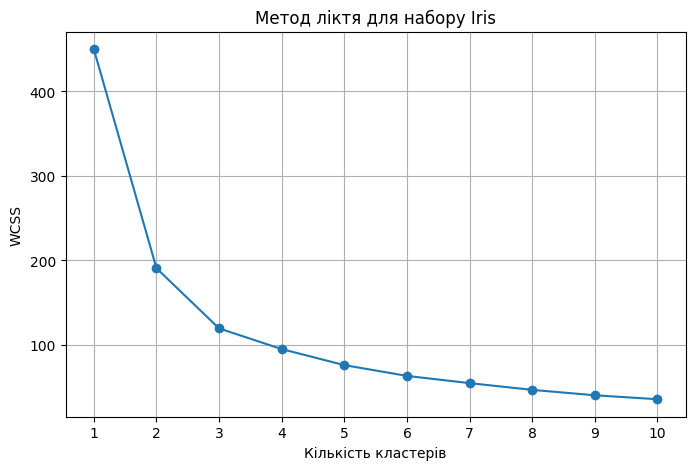

In [5]:
X_iris = iris_df.iloc[:, :3]

scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss_iris = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_iris_scaled)
    wcss_iris.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_iris, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.title('Метод ліктя для набору Iris')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

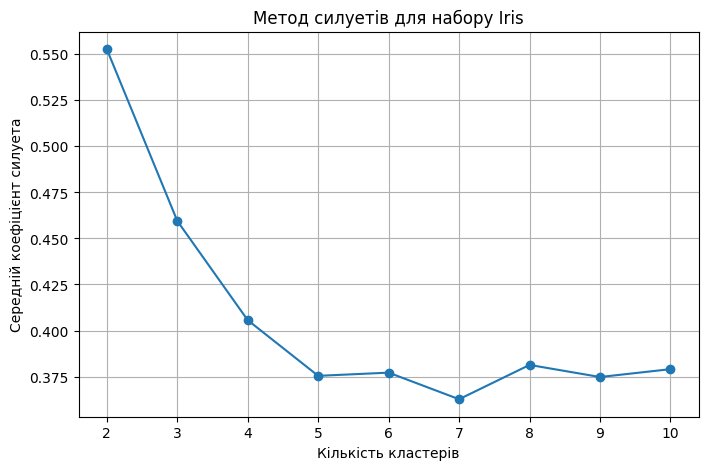

Найкраща кількість кластерів за силуетом: 2


In [6]:
silhouette_iris = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_iris_scaled)
    silhouette_iris.append(silhouette_score(X_iris_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_iris, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів для набору Iris')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

print('Найкраща кількість кластерів за силуетом:',
      range(2, 11)[int(np.argmax(silhouette_iris))] if 'np' in globals()
      else list(range(2, 11))[silhouette_iris.index(max(silhouette_iris))])

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

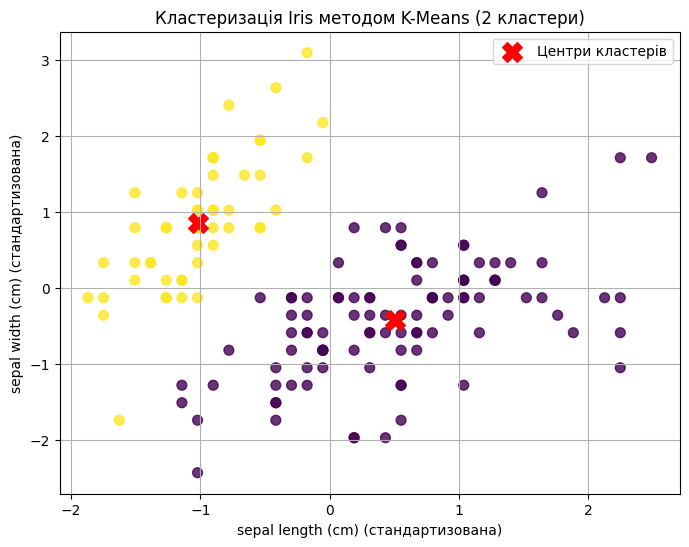

Кількість об’єктів у кожному кластері:
0    100
1     50
Name: count, dtype: int64


In [7]:
kmeans_iris = KMeans(n_clusters=2, random_state=42, n_init=10)
iris_clusters = kmeans_iris.fit_predict(X_iris_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1],
            c=iris_clusters, cmap='viridis', s=50, alpha=0.8)
centers = kmeans_iris.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X',
            s=200, label='Центри кластерів')
plt.xlabel(iris.feature_names[0] + ' (стандартизована)')
plt.ylabel(iris.feature_names[1] + ' (стандартизована)')
plt.title('Кластеризація Iris методом K-Means (2 кластери)')
plt.legend()
plt.grid(True)
plt.show()

print('Кількість об’єктів у кожному кластері:')
print(pd.Series(iris_clusters).value_counts().sort_index())

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [9]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [10]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [11]:
print('Назви стовпців:')
print(df.columns.tolist())

Назви стовпців:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [13]:
print('Кількість пропущених значень у кожному стовпці:')
print(df.isnull().sum())
print('\nЗагальна кількість пропущених значень:', df.isnull().sum().sum())

Кількість пропущених значень у кожному стовпці:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Загальна кількість пропущених значень: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [14]:
print('Кількість дублікатів:', df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [15]:
df.describe(include='all')

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [16]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Розмір навчальної вибірки:', X_train.shape)
print('Розмір тестової вибірки:', X_test.shape)

Розмір навчальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [20]:
rf = RandomForestClassifier(random_state=42)
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(rf, rf_params, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train, y_train)

rf_best = rf_grid.best_estimator_
rf_pred = rf_best.predict(X_test)
rf_cv = rf_grid.best_score_
rf_accuracy = accuracy_score(y_test, rf_pred)

print('Найкращі параметри Random Forest:', rf_grid.best_params_)
print('Середня CV-точність:', round(rf_cv, 4))
print('Тестова accuracy:', round(rf_accuracy, 4))

Найкращі параметри Random Forest: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9205
Тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [21]:
lr = LogisticRegression(solver='saga', max_iter=5000, random_state=42)
lr_params = {
    'C': [0.1, 1, 10],
    'penalty': ['l1', 'l2']
}
lr_grid = GridSearchCV(lr, lr_params, cv=5, scoring='accuracy', n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)

lr_best = lr_grid.best_estimator_
lr_pred = lr_best.predict(X_test_scaled)
lr_cv = lr_grid.best_score_
lr_accuracy = accuracy_score(y_test, lr_pred)

print('Найкращі параметри Logistic Regression:', lr_grid.best_params_)
print('Середня CV-точність:', round(lr_cv, 4))
print('Тестова accuracy:', round(lr_accuracy, 4))

Найкращі параметри Logistic Regression: {'C': 0.1, 'penalty': 'l1'}
Середня CV-точність: 0.8024
Тестова accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [22]:
svm = SVC()
svm_params = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(svm, svm_params, cv=5, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)

svm_best = svm_grid.best_estimator_
svm_pred = svm_best.predict(X_test_scaled)
svm_cv = svm_grid.best_score_
svm_accuracy = accuracy_score(y_test, svm_pred)

print('Найкращі параметри SVM:', svm_grid.best_params_)
print('Середня CV-точність:', round(svm_cv, 4))
print('Тестова accuracy:', round(svm_accuracy, 4))

Найкращі параметри SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8521
Тестова accuracy: 0.858


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [23]:
results = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV accuracy': [rf_cv, lr_cv, svm_cv],
    'Test accuracy': [rf_accuracy, lr_accuracy, svm_accuracy]
})
display(results.sort_values('CV accuracy', ascending=False))

best_name = results.loc[results['CV accuracy'].idxmax(), 'Модель']
predictions = {
    'Random Forest': rf_pred,
    'Logistic Regression': lr_pred,
    'SVM': svm_pred
}
print('Найкраща модель за CV-точністю:', best_name)
print('\nЗвіт класифікації для найкращої моделі:')
print(classification_report(y_test, predictions[best_name]))

,Модель,CV accuracy,Test accuracy
0,Random Forest,0.920549,0.910230
2,SVM,0.852065,0.858038
1,Logistic Regression,0.802411,0.818372


Найкраща модель за CV-точністю: Random Forest

Звіт класифікації для найкращої моделі:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

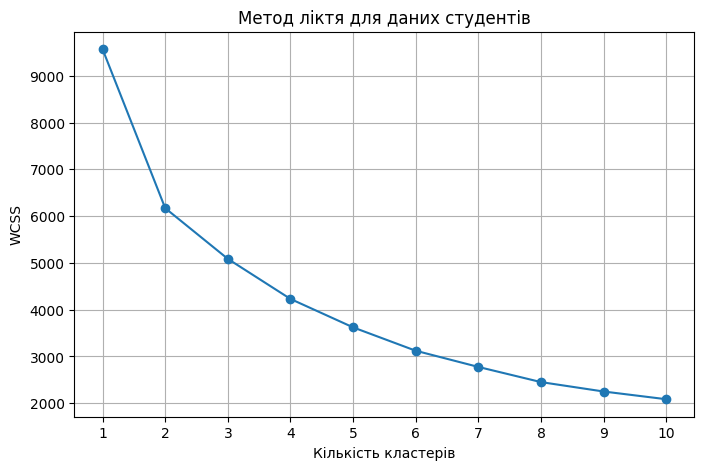

In [24]:
cluster_features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_students_cluster = df[cluster_features]

scaler_cluster = StandardScaler()
X_students_scaled = scaler_cluster.fit_transform(X_students_cluster)

wcss_students = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_students_scaled)
    wcss_students.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_students, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.title('Метод ліктя для даних студентів')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

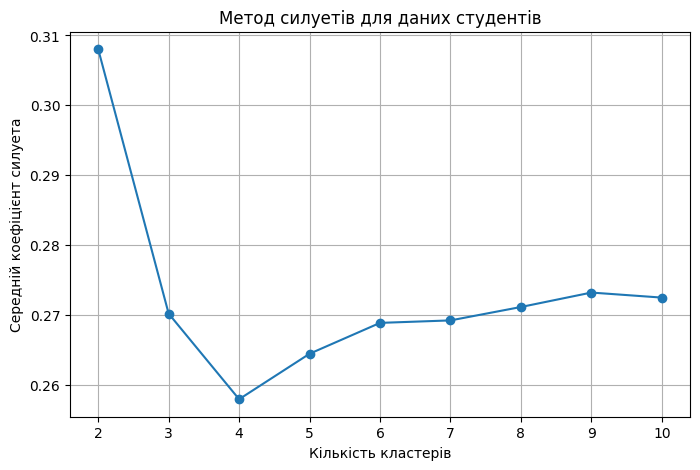

Найкраща кількість кластерів за силуетом: 2


In [25]:
silhouette_students = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_students_scaled)
    silhouette_students.append(silhouette_score(X_students_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_students, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів для даних студентів')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

best_k_silhouette = list(range(2, 11))[int(silhouette_students.index(max(silhouette_students)))]
print('Найкраща кількість кластерів за силуетом:', best_k_silhouette)

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [26]:
%pip -q install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [27]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [28]:
X_pca = df.drop(columns=['StudentID', 'GradeClass'])
print('Кількість ознак для PCA:', X_pca.shape[1])
print('Розмір набору даних:', X_pca.shape)

Кількість ознак для PCA: 13
Розмір набору даних: (2392, 13)


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [29]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)

pca = PCA()
X_pca_all = pca.fit_transform(X_pca_scaled)
explained_variance = pca.explained_variance_ratio_

print('Частка поясненої дисперсії кожної компоненти:')
print(explained_variance)

Частка поясненої дисперсії кожної компоненти:
[0.15246911 0.0861136  0.08267885 0.08071826 0.07864825 0.07793075
 0.0763079  0.07600434 0.07440892 0.0737979  0.07167781 0.06746103
 0.00178329]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

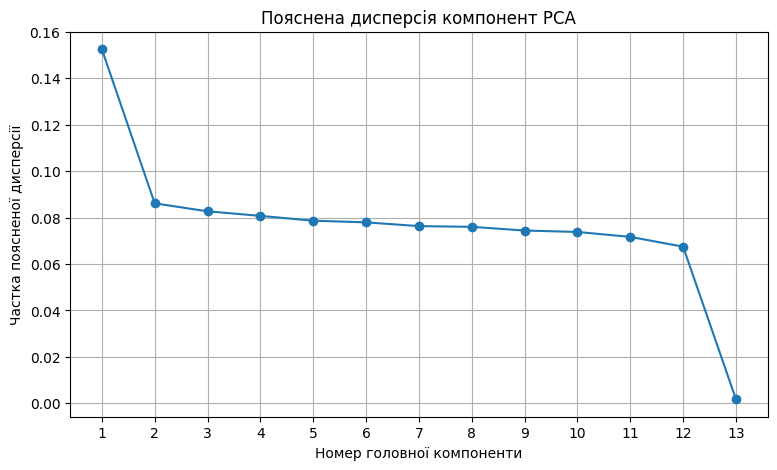

Кількість компонент за KneeLocator: 2
Вибрана кількість компонент: 2


In [30]:
component_numbers = np.arange(1, len(explained_variance) + 1)

plt.figure(figsize=(9, 5))
plt.plot(component_numbers, explained_variance, marker='o')
plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.title('Пояснена дисперсія компонент PCA')
plt.xticks(component_numbers)
plt.grid(True)
plt.show()

knee = KneeLocator(
    component_numbers, explained_variance,
    curve='convex', direction='decreasing'
)
n_components_knee = knee.knee
if n_components_knee is None:
    n_components_knee = int(np.argmax(np.cumsum(explained_variance) >= 0.80) + 1)
    print('Точку ліктя автоматично не знайдено; використано мінімальну кількість компонент для 80% дисперсії.')
else:
    print('Кількість компонент за KneeLocator:', n_components_knee)

print('Вибрана кількість компонент:', n_components_knee)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

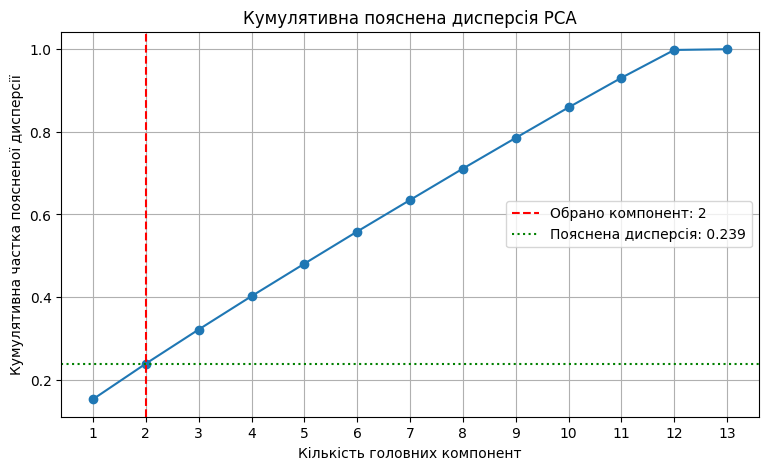

Фактична частка поясненої дисперсії: 0.2386
Розмір даних після PCA: (2392, 2)


In [31]:
cumulative_variance = np.cumsum(explained_variance)
actual_variance = cumulative_variance[n_components_knee - 1]

plt.figure(figsize=(9, 5))
plt.plot(component_numbers, cumulative_variance, marker='o')
plt.axvline(n_components_knee, color='red', linestyle='--',
            label=f'Обрано компонент: {n_components_knee}')
plt.axhline(actual_variance, color='green', linestyle=':',
            label=f'Пояснена дисперсія: {actual_variance:.3f}')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка поясненої дисперсії')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xticks(component_numbers)
plt.grid(True)
plt.legend()
plt.show()

print(f'Фактична частка поясненої дисперсії: {actual_variance:.4f}')
pca_selected = PCA(n_components=n_components_knee, random_state=42)
X_pca_selected = pca_selected.fit_transform(X_pca_scaled)
print('Розмір даних після PCA:', X_pca_selected.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [32]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

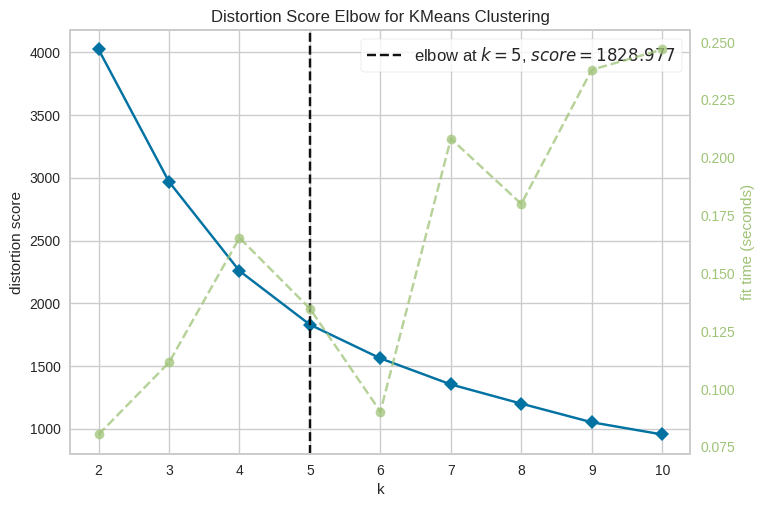

Оптимальна кількість кластерів за KElbowVisualizer: 5


In [33]:
kmeans_pca = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(kmeans_pca, k=(2, 11), metric='distortion')
visualizer.fit(X_pca_selected)
visualizer.show()

print('Оптимальна кількість кластерів за KElbowVisualizer:',
      visualizer.elbow_value_)

Висновки

У лабораторній роботі було досліджено метод K-Means, метод ліктя, коефіцієнт силуета та метод головних компонент PCA.

У першому завданні виконано кластеризацію набору Iris за трьома ознаками. Метод ліктя допомагає оцінити кількість кластерів за зміною WCSS, а коефіцієнт силуета — за якістю розділення кластерів. Фінальну модель побудовано для двох кластерів, а результат відображено на площині за першими двома ознаками.

У другому завданні спочатку розв’язано задачу класифікації: цільова змінна GradeClass використовувалася для навчання Random Forest, Logistic Regression та SVM. Моделі порівнювалися за CV-точністю та тестовою accuracy. Далі виконано кластеризацію, у якій GradeClass не використовувалася: алгоритм шукав групи студентів за числовими характеристиками Age, StudyTimeWeekly, Absences та GPA.

 На завершальному етапі застосовано PCA до всіх ознак, крім StudentID та GradeClass. Кількість головних компонент визначено за допомогою KneeLocator (або резервного правила, якщо точку ліктя не знайдено), після чого побудовано кумулятивну пояснену дисперсію та виконано пошук кількості кластерів за допомогою KElbowVisualize.
Числові результати — найкраща модель, оптимальна кількість кластерів, кількість компонент PCA та частка поясненої дисперсії — виводяться під час виконання комірок і залежать від фактичного набору даних.